In [1]:
from pathlib import Path
import shutil

data_file = Path("data/HI-Small_Trans.csv")

if not data_file.is_file():
    # Install once if needed: %pip install kagglehub
    import kagglehub

    downloaded_file = kagglehub.dataset_download(
        "ealtman2019/ibm-transactions-for-anti-money-laundering-aml",
        path="HI-Small_Trans.csv",
    )

    data_file.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy2(downloaded_file, data_file)

print(f"Data ready: {data_file}")

Data ready: data/HI-Small_Trans.csv


In [2]:
import numpy as np
from scipy import linalg
import scipy.sparse as sp
import numpy as np
import scipy.sparse as sparse
import scipy.sparse.linalg as spla

class BoundaryNotPresentError(Exception):
    pass

def build_boundary_matrix(n_tuples, n_plus_1_tuples):
    """
    Builds a sparse boundary matrix from two lists of tuples.

    Args:
        n_tuples: List of tuples of length n
        n_plus_1_tuples: List of tuples of length n+1

    Returns:
        scipy.sparse.csr_matrix: Sparse matrix where rows correspond to n_tuples 
                                and columns correspond to n_plus_1_tuples

    Raises:
        ValueError: If input tuples have invalid lengths
        BoundaryNotPresentError: If a boundary is not found in n_tuples
    """
    # Verify input lengths
    if not n_tuples or not n_plus_1_tuples:
        return sparse.csr_matrix((0, 0))

    n = len(n_tuples[0])
    if any(len(t) != n for t in n_tuples) or any(len(t) != n + 1 for t in n_plus_1_tuples):
        raise ValueError("Invalid tuple lengths")

    # Create a dictionary for quick lookup of n_tuples
    n_tuple_dict = {tuple(t): i for i, t in enumerate(n_tuples)}

    # Initialize lists for sparse matrix construction
    rows = []
    cols = []
    data = []

    # Build matrix column by column
    for col, n_plus_1_tuple in enumerate(n_plus_1_tuples):
        for i in range(n + 1):
            # Create boundary by removing element at position i
            boundary = n_plus_1_tuple[:i] + n_plus_1_tuple[i + 1:]
            try:
                row = n_tuple_dict[tuple(boundary)]
            except KeyError:
                raise BoundaryNotPresentError(
                    f"Boundary {boundary} from {n_plus_1_tuple} not found in n_tuples"
                )
            coefficient = (-1) ** (i + 1)
            rows.append(row)
            cols.append(col)
            data.append(coefficient)

    # Create sparse matrix in COO format and convert to CSR
    matrix = sparse.coo_matrix(
        (data, (rows, cols)), 
        shape=(len(n_tuples), len(n_plus_1_tuples))
    )
    return matrix.tocsr()
    
def sparse_lift_representative(representative, nm1_simplices, n_simplices):
    """
    Memory-efficient version of lift_representative that computes only the
    necessary columns of the boundary matrix.
    
    Args:
        representative: List of n-simplices that form the representative
        nm1_simplices: List of (n-1)-simplices
        n_simplices: List of n-simplices
        
    Returns:
        numpy.ndarray: A vector in the null space of the boundary matrix
    """
    # Get indices of simplices in the representative
    basis_index = np.sort([n_simplices.index(simp) for simp in representative])
    
    # Build only the columns we need (instead of the full boundary matrix)
    columns = []
    for idx in basis_index:
        n_plus_1_tuple = n_simplices[idx]
        column = np.zeros(len(nm1_simplices), dtype=np.float64)  # Explicitly use float64
        
        # Generate boundaries and fill the column
        for i in range(len(n_plus_1_tuple)):
            # Create boundary by removing element at position i
            boundary = n_plus_1_tuple[:i] + n_plus_1_tuple[i+1:]
            try:
                row = nm1_simplices.index(boundary)
                # Calculate coefficient and assign to column
                coefficient = (-1) ** (i + 1)
                column[row] = float(coefficient)  # Ensure floating point
            except ValueError:
                raise BoundaryNotPresentError(
                    f"Boundary {boundary} from {n_plus_1_tuple} not found in nm1_simplices"
                )
        
        columns.append(column)
    
    # Form the matrix A directly from columns as float64
    A = np.column_stack(columns).astype(np.float64)
    
    # Determine best approach based on matrix size
    if min(A.shape) <= 1:
        # Handle degenerate case
        x_orig = np.zeros(len(n_simplices), dtype=np.float64)
        if A.shape[1] > 0:
            x_orig[basis_index] = 1.0
        return x_orig
    
    # Choose appropriate SVD method based on matrix size
    if max(A.shape) < 1000:  # Threshold can be adjusted
        # For small matrices, use full SVD
        u, s, vh = np.linalg.svd(A, full_matrices=True)
        tol = max(A.shape) * np.finfo(float).eps * np.max(s) if s.size > 0 else 1e-10
        null_mask = (s <= tol)
        
        if not np.any(null_mask):
            # No null space found
            return np.zeros(len(n_simplices), dtype=np.float64)
            
        null_space_A = vh[null_mask].T
    else:
        # For larger matrices, use sparse SVD to compute smallest singular values
        try:
            # Convert to sparse matrix if not already
            if not sp.issparse(A):
                A_sparse = sp.csr_matrix(A)
            else:
                A_sparse = A
                
            # Number of vectors to compute; this can be adjusted
            k = min(5, min(A_sparse.shape)-1)
            if k <= 0:
                return np.zeros(len(n_simplices), dtype=np.float64)
                
            # Compute a few singular vectors corresponding to smallest singular values
            u, s, vt = spla.svds(A_sparse, k=k, which='SM')
            
            # Check if null space exists (smallest singular value ≈ 0)
            if not np.any(np.isclose(s, 0)):
                return np.zeros(len(n_simplices), dtype=np.float64)
                
            # Get the vector corresponding to the smallest singular value
            null_idx = np.argmin(s)
            null_space_A = vt[null_idx:null_idx+1, :].T
            
        except Exception as e:
            # Fall back to dense SVD if sparse fails
            print(f"Sparse SVD failed, falling back to dense computation: {e}")
            u, s, vh = np.linalg.svd(A, full_matrices=True)
            tol = max(A.shape) * np.finfo(float).eps * np.max(s) if s.size > 0 else 1e-10
            null_mask = (s <= tol)
            
            if not np.any(null_mask):
                # No null space found
                return np.zeros(len(n_simplices), dtype=np.float64)
                
            null_space_A = vh[null_mask].T
    
    # Handle empty null space
    if null_space_A.size == 0 or null_space_A.shape[1] == 0:
        return np.zeros(len(n_simplices), dtype=np.float64)
    
    # If we have multiple vectors in the null space,
    # choose the one with the most non-zero entries
    if null_space_A.shape[1] > 1:
        nonzero_entries = np.count_nonzero(~np.isclose(null_space_A, 0), axis=0)
        sparse_column = null_space_A[:, np.argmax(nonzero_entries)]
    else:
        sparse_column = null_space_A.flatten()
    
    # Normalize the vector
    max_abs = np.max(np.abs(sparse_column))
    if max_abs > 0:
        lifted_vector = sparse_column / max_abs
    else:
        lifted_vector = sparse_column
    
    # Create full vector
    x_orig = np.zeros(len(n_simplices), dtype=np.float64)
    x_orig[basis_index] = lifted_vector
    
    return x_orig

In [8]:
import numpy as np
import pulp
import scipy.sparse as sparse

def find_minimal_homologous_cycle(
    boundary_matrix, x_orig, W=None, use_gurobi=True, verbose=True
):
    """
    Solve the weighted linear optimization problem for finding a minimal homologous cycle.

    Parameters:
    - boundary_matrix: The boundary matrix (dense or sparse) mapping (n+1)-simplices to n-simplices
    - x_orig: The original cycle of n-simplices
    - W: Weight matrix for the objective function (default: None for unweighted)

    Returns:
    - x_solution: The minimal homologous cycle
    - status: The optimization status
    - objective_value: The weighted L1 norm of the minimal homologous cycle
    """
    # Dimensions
    m, n = boundary_matrix.shape

    # Check and prepare the weight matrix
    if isinstance(W, np.ndarray) and W.shape != (m, m):
        raise ValueError(f"W must be a square matrix of size {m}x{m}")

    # Convert boundary_matrix to sparse if it isn't already
    if not sparse.issparse(boundary_matrix):
        boundary_matrix = sparse.csr_matrix(boundary_matrix)

    # Create the LP problem
    prob = pulp.LpProblem("Weighted_Minimal_Homologous_Cycle", pulp.LpMinimize)

    # Decision variables
    x_plus = [pulp.LpVariable(f"x_plus_{i}", lowBound=0) for i in range(m)]
    x_minus = [pulp.LpVariable(f"x_minus_{i}", lowBound=0) for i in range(m)]
    q = [pulp.LpVariable(f"q_{i}", cat="Continuous") for i in range(n)]

    # Objective function
    if W is None:
        prob += pulp.lpSum(x_plus) + pulp.lpSum(x_minus)
    else:
        w = np.sum(W, axis=0)
        prob += pulp.lpSum(w[j] * (x_plus[j] + x_minus[j]) for j in range(m))

    # Constraints
    for i in range(m):
        row = boundary_matrix.getrow(i)
        indices = row.indices
        data = row.data
        prob += x_plus[i] - x_minus[i] == x_orig[i] + pulp.lpSum(
            data[k] * q[indices[k]] for k in range(len(indices))
        )

    print("\tRunning the solver...")
    # Solve the problem
    if use_gurobi:
        solver = pulp.getSolver("GUROBI_CMD", msg=verbose)
    else:
        solver = pulp.PULP_CBC_CMD(msg=verbose)
    prob.solve(solver)

    # Extract the solution
    x_solution = np.array(
        [pulp.value(x_plus[i]) - pulp.value(x_minus[i]) for i in range(m)]
    )

    return x_solution, prob.status, pulp.value(prob.objective)


import numpy as np
import pulp
from scipy import sparse

def find_time_minimal_homologous_cycle(
    boundary_matrix, x_orig, W=None, inv_row_map=None, adj_matrix=None, use_gurobi=True, verbose=True
):
    """
    Solve the weighted linear optimization problem for finding a minimal homologous cycle.

    Parameters:
    - boundary_matrix: The boundary matrix (dense or sparse) mapping (n+1)-simplices to n-simplices
    - x_orig: The original cycle of n-simplices
    - W: Weight matrix for the objective function (default: None)
    - inv_row_map: List of simplices (tuples of indices), used with adj_matrix to compute weights if W is None
    - adj_matrix: Adjacency matrix, used with inv_row_map to compute weights if W is None
    - use_gurobi: Whether to use Gurobi solver (default: True)
    - verbose: Whether to show solver output (default: True)

    Returns:
    - x_solution: The minimal homologous cycle
    - status: The optimization status
    - objective_value: The weighted L1 norm of the minimal homologous cycle
    """
    # Dimensions
    m, n = boundary_matrix.shape

    # Convert boundary_matrix to sparse if it isn't already
    if not sparse.issparse(boundary_matrix):
        boundary_matrix = sparse.csr_matrix(boundary_matrix)

    # Create the LP problem
    prob = pulp.LpProblem("Weighted_Minimal_Homologous_Cycle", pulp.LpMinimize)

    # Decision variables
    x_plus = [pulp.LpVariable(f"x_plus_{i}", lowBound=0) for i in range(m)]
    x_minus = [pulp.LpVariable(f"x_minus_{i}", lowBound=0) for i in range(m)]
    q = [pulp.LpVariable(f"q_{i}", cat="Continuous") for i in range(n)]

    # Compute weights
    if W is not None:
        # Use provided weight matrix
        if isinstance(W, np.ndarray) and W.shape != (m, m):
            raise ValueError(f"W must be a square matrix of size {m}x{m}")
        w = np.sum(W, axis=0)
    elif inv_row_map is not None and adj_matrix is not None:
        # Compute w directly without creating the full weight matrix
        v = np.array([adj_matrix[s[0]][s[1]] for s in inv_row_map])
        v_sorted = np.sort(v)
        s_left = np.cumsum(v_sorted)  # Cumulative sum from left
        s_right = np.cumsum(v_sorted[::-1])[::-1]  # Cumulative sum from right
        left = np.searchsorted(v_sorted, v, side='left')  # Indices where v[j] would insert (left)
        right = np.searchsorted(v_sorted, v, side='right')  # Indices where v[j] would insert (right)
        
        # Sum of values less than v[j]
        sum_less = np.zeros(m)
        mask_less = left > 0
        sum_less[mask_less] = s_left[left[mask_less] - 1]
        
        # Sum of values greater than v[j]
        sum_greater = np.zeros(m)
        mask_greater = right < m
        sum_greater[mask_greater] = s_right[right[mask_greater]]
        
        # Number of values less than and greater than v[j]
        num_less = left
        num_greater = m - right
        
        # Compute w[j] = sum_k |v[j] - v[k]|
        w = (num_less * v - sum_less) + (sum_greater - num_greater * v)
    else:
        # Unweighted case
        w = np.ones(m)

    # Objective function
    prob += pulp.lpSum(w[j] * (x_plus[j] + x_minus[j]) for j in range(m))

    # Constraints
    for i in range(m):
        row = boundary_matrix.getrow(i)
        indices = row.indices
        data = row.data
        prob += x_plus[i] - x_minus[i] == x_orig[i] + pulp.lpSum(
            data[k] * q[indices[k]] for k in range(len(indices))
        )

    print("\tRunning the solver...")
    # Solve the problem
    if use_gurobi:
        solver = pulp.getSolver("GUROBI_CMD", msg=verbose)
    else:
        solver = pulp.PULP_CBC_CMD(msg=verbose)
    prob.solve(solver)

    # Extract the solution
    x_solution = np.array(
        [pulp.value(x_plus[i]) - pulp.value(x_minus[i]) for i in range(m)]
    )

    return x_solution, prob.status, pulp.value(prob.objective)

In [9]:
def sparse_prepare_optimization(gudhi_complex, reduced_boundary_base, representative,dimension):
    birth_simplex = representative["birth"]
    try:
        death_simplex = representative["death"]
    except KeyError:
        death_simplex= None
    representative = representative["representative"]
    
    # Get the ACTUAL values of birth and death
    birth = gudhi_complex.filtration(birth_simplex)
    if death_simplex is not None:
        death = gudhi_complex.filtration(death_simplex)
    else:
        death = 1.1
    min_persistence = (death - birth)*0.5
    
    order_function = lambda s: (gudhi_complex.filtration(s), s)
    # ISOLATED
    np1_simplices = sorted(
        {
            simplex
            for simplex in reduced_boundary_base
            if gudhi_complex.filtration(simplex) <= (death - min_persistence)*1.01 #slack for rounding errors
        },
        key=order_function,
    )
    if len(np1_simplices)==0:
        print("No Triangles exist at birth time")
    else:
        print(f"Available Triangles: {len(np1_simplices)}")
    n_simplices = sorted(
        {
            tuple(sorted(simplex))
            for simplex, radius in gudhi_complex.get_filtration()
            if len(simplex) == dimension and radius <= (death - min_persistence)*1.01 #slack for rounding errors
        },
        key=order_function,
    )
    nm1_simplices = sorted(
        {
            tuple(sorted(simplex))
            for simplex, radius in gudhi_complex.get_filtration()
            if len(simplex) == dimension - 1 and radius <= (death - min_persistence)*1.01 #slack for rounding errors
        },
        key=order_function,
    )
    print("\tLifting...")
    x_orig = sparse_lift_representative(representative, nm1_simplices, n_simplices)
    print("\tCreating boundary matrix...")
    #boundary_matrix = re.core.build_boundary_matrix(n_simplices, np1_simplices)
    boundary_matrix = build_boundary_matrix(n_simplices,np1_simplices)
    
    return x_orig,n_simplices,boundary_matrix

In [40]:
import pandas as pd
import networkx as nx
import numpy as np
import recycle as re
import itertools
def get_all_representatives(gudhi_complex, dimension =2):
    # Construct boundary map: simplex -> set of (dim-1)-simplices in its boundary
    boundary_map = {
        tuple(sorted(simplex)): set(
            itertools.combinations(tuple(sorted(simplex)), len(simplex) - 1)
        ) - {tuple()}
        for simplex, radius in gudhi_complex.get_filtration()
    }
    
    # Initialize R (reduced boundary matrix columns) and V (cycle representatives)
    R = {k: v for k, v in boundary_map.items()}
    V = {k: {k} for k in boundary_map}  # V[s] tracks the cycle containing simplex s
    lowinv = {}  # Maps birth simplex to death simplex
    order_function = lambda s: (gudhi_complex.filtration(s), s)  # Sort by filtration
    
    # Matrix reduction algorithm
    for s in sorted(R, key=order_function):
        t = lowinv.get(max(R[s], key=order_function), -1) if len(R[s]) != 0 else -1
        while t != -1:
            R[s] = R[s] ^ R[t]  # Update R[s] by symmetric difference
            V[s] = V[s] ^ V[t]  # Update V[s] to maintain cycle representatives
            t = lowinv.get(max(R[s], key=order_function), -1) if len(R[s]) != 0 else -1
        if len(R[s]) != 0:
            lowinv[max(R[s], key=order_function)] = s  # Record persistence pair
    
    # Collect finite persistence representatives
    finite_representatives = []
    persistence_values = []
    for birth, death in lowinv.items():
        if len(birth) == dimension :  # Birth simplex is a k-simplex
            persistence = gudhi_complex.filtration(death) - gudhi_complex.filtration(birth)
            if persistence==0:
                continue
            representative = V[birth]  # Representative cycle for the pair
            finite_representatives.append({
                'birth': birth,
                'death': death,
                'persistence': persistence,
                'representative': representative
            })
            persistence_values.append(persistence)
    
    # Collect infinite persistence representatives
    infinite_representatives = []
    for s in boundary_map:
        if (len(s) == dimension and 
            len(R[s]) == 0 and 
            s not in lowinv.keys()):  # Unpaired k-simplices
            representative = V[s]
            infinite_representatives.append({
                'birth': s,
                'representative': representative
            })
    # Get reduced boundary base
    reduced_boundary_base = {
        simplex
        for simplex, boundary in R.items()
        if len(simplex) == dimension + 1 and len(boundary) > 0
    }
    return finite_representatives, infinite_representatives,boundary_map, reduced_boundary_base

def create_transaction_net(df):
    # Sort by timestamp
    df["Timestamp"] =pd.to_datetime(df["Timestamp"])
    df = df.sort_values('Timestamp')
    
    # Get unique accounts in order of first appearance
    all_accounts = []
    seen = set()
    for _, row in df.iterrows():
        for account in [row['Account'], row['Account.1']]:
        #for account in [row['From Bank'], row['To Bank']]:
            if account not in seen:
                all_accounts.append(account)
                seen.add(account)
    
    # Create a mapping of account to index
    account_to_index = {account: idx for idx, account in enumerate(all_accounts)}
    
    # Normalize timestamps to 0-1 range
    min_timestamp = df['Timestamp'].min()
    max_timestamp = df['Timestamp'].max()
    time_range = max_timestamp - min_timestamp
    df['normalized_time'] = [(t - min_timestamp).total_seconds() / time_range.total_seconds() 
                             for t in df['Timestamp']]
    
    # Create an undirected graph
    G = nx.Graph()
    
    # Add nodes with account info as attribute
    for account, idx in account_to_index.items():
        G.add_node(idx, account=account)
    
    # Check if there are any self-transactions
    self_transactions = df[df['Account'] == df['Account.1']]
    #self_transactions = df[df['From Bank'] == df['To Bank']]
    if not self_transactions.empty:
        print(f"Warning: Found {len(self_transactions)} transactions where account sends to itself.")
        
    # Add edges with weights (using first transaction's weight for repeated pairs)
    edge_weights = {}  # To track first transaction between each pair
    for _, row in df.iterrows():
        #source_idx = account_to_index[row['From Bank']]
        #target_idx = account_to_index[row['To Bank']]
        source_idx = account_to_index[row['Account']]
        target_idx = account_to_index[row['Account.1']]
        weight = row['normalized_time']
        
        # Skip self-loops (transactions from an account to itself)
        if source_idx == target_idx:
            continue
        
        # For undirected graph, use first transaction's weight
        edge_key = tuple(sorted([source_idx, target_idx]))  # Ensure consistent key for undirected edges
        if edge_key not in edge_weights:
            edge_weights[edge_key] = weight
            G.add_edge(source_idx, target_idx, weight=weight)
    
    # Create adjacency matrix
    adj_matrix = nx.to_numpy_array(G)
    
    return G, adj_matrix, account_to_index

import gudhi
def create_clique_complex(G):
    # Get all edges with their weights (sort node pairs for consistency)
    edges_with_weights = [(min(u, v), max(u, v), data.get('weight', 1)) 
                         for u, v, data in G.edges(data=True)]
    
    # Create a weight lookup dictionary with sorted node pairs
    weight_dict = {(min(u, v), max(u, v)): w for u, v, w in edges_with_weights}
    
    # Get all triangles using NetworkX's clique enumeration
    triangles = [c for c in nx.enumerate_all_cliques(G) if len(c) == 3]
    
    # Calculate the weight of each triangle
    triangles_with_weights = []
    for triangle in triangles:
        u, v, w = sorted(triangle)  # Sort nodes within the triangle
        
        # Create sorted edge pairs for lookups
        edge1 = (u, v)  # Already sorted because u < v after triangle sorting
        edge2 = (u, w)  # Already sorted because u < w after triangle sorting
        edge3 = (v, w)  # Already sorted because v < w after triangle sorting
        
        # Get weights using sorted edges
        edge1_weight = weight_dict[edge1]
        edge2_weight = weight_dict[edge2]
        edge3_weight = weight_dict[edge3]
        
        triangle_weight = max(edge1_weight, edge2_weight, edge3_weight)
        triangles_with_weights.append(((u, v, w), triangle_weight))
    
    st = gudhi.SimplexTree()
    for node in G.nodes():
        st.insert([node])
    for (n1,n2,timestamp) in edges_with_weights:
        st.insert([n1,n2],filtration=timestamp)
    for ((n1,n2,n3), timestamp) in triangles_with_weights:
        st.insert([n1,n2,n3],filtration=timestamp)
    return st

def prepare_optimization(gudhi_complex, reduced_boundary_base, representative,dimension):
    birth_simplex = representative["birth"]
    try:
        death_simplex = representative["death"]
    except KeyError:
        death_simplex= None
    representative = representative["representative"]
    
    # Get the ACTUAL values of birth and death
    birth = gudhi_complex.filtration(birth_simplex)
    if death_simplex is not None:
        death = gudhi_complex.filtration(death_simplex)
    else:
        death = 1.1
    min_persistence = (death - birth)*0.6
    
    order_function = lambda s: (gudhi_complex.filtration(s), s)
    # ISOLATED
    np1_simplices = sorted(
        {
            simplex
            for simplex in reduced_boundary_base
            if gudhi_complex.filtration(simplex) <= (death - min_persistence)*1.01 #slack for rounding errors
        },
        key=order_function,
    )
    if len(np1_simplices)==0:
        print("No Triangles exist at birth time")
    else:
        print(f"Available Triangles: {len(np1_simplices)}")
    n_simplices = sorted(
        {
            tuple(sorted(simplex))
            for simplex, radius in gudhi_complex.get_filtration()
            if len(simplex) == dimension and radius <= (death - min_persistence)*1.01 #slack for rounding errors
        },
        key=order_function,
    )
    nm1_simplices = sorted(
        {
            tuple(sorted(simplex))
            for simplex, radius in gudhi_complex.get_filtration()
            if len(simplex) == dimension - 1 and radius <= (death - min_persistence)*1.01 #slack for rounding errors
        },
        key=order_function,
    )
    print("\tLifting...")
    x_orig = re.core.lift_representative(representative, nm1_simplices, n_simplices)
    print("\tCreating boundary matrix...")
    boundary_matrix = re.core.build_boundary_matrix(n_simplices, np1_simplices)
    return x_orig,n_simplices,boundary_matrix

def incident_accounts(df, cycle,index_to_account):
    account_pairs = [(index_to_account[a], index_to_account[b]) for (a,b) in cycle]
  
    # Create an empty dataframe to store results
    filtered_df = pd.DataFrame(columns=df.columns)
    
    # Process each banker pair
    for id1, id2 in account_pairs:
        # Find rows where from=id1 and to=id2 OR from=id2 and to=id1
        pair_condition = (
            ((df['Account'] == id1) & (df['Account.1'] == id2)) | 
            ((df['Account'] == id2) & (df['Account.1'] == id1))
        )
        matching_rows = df[pair_condition]
        
        # Append these rows to the result
        filtered_df = pd.concat([filtered_df, matching_rows], ignore_index=True)
    
    return filtered_df


def create_weight_matrix_vectorized(inv_row_map, adj_matrix):
    """
    Ultra-fast implementation that computes the entire weight matrix
    in one vectorized operation.
    
    Args:
        inv_row_map: List of simplices (tuples of indices)
        adj_matrix: Original adjacency matrix
        
    Returns:
        numpy.ndarray: Weight matrix with time differences
    """
    n = len(inv_row_map)
    
    # Pre-compute all matrix values for each simplex in one pass
    simplex_values = np.array([adj_matrix[s[0]][s[1]] for s in inv_row_map])
    
    # Create the entire weight matrix using broadcasting
    # This computes all pairwise absolute differences in one operation
    weight_matrix = np.abs(simplex_values.reshape(-1, 1) - simplex_values.reshape(1, -1))
    
    return weight_matrix

def time_matrix(matrix):
    def inner_time_matrix(simplex_j, simplex_i):
        a = matrix[simplex_i[0]][simplex_i[1]]
        b = matrix[simplex_j[0]][simplex_j[1]]
        return np.abs(a - b)
    return inner_time_matrix

In [41]:
print("\tReading dataframe...")
df = pd.read_csv("data/HI-Small_Trans.csv")
df_illicit = df[df["Is Laundering"]==1]

print("\tBuilding shady dataframe...")
shady_accounts = np.union1d(df_illicit["Account"],df_illicit["Account.1"])
shady_accounts = shady_accounts[:6000]
shady_df = df[np.logical_or(df["Account"].isin(shady_accounts),df["Account.1"].isin(shady_accounts))]

print("\tCleaning memory...")
del df
del df_illicit

print("\tBuilding simplicial complex..")
G, adj_matrix, account_to_index = create_transaction_net(shady_df)
index_to_account = {idx:acc for (acc,idx) in account_to_index.items()}
gudhi_complex = create_clique_complex(G)

print("\tCleaning memory...")
#del G
del shady_df

print("\tComputing homology...")
dimension = 2
points = adj_matrix
#gudhi_complex = re.core.create_simplicial_complex(points, 1, dimension,distance_matrix=True)
finite_representatives, infinite_representatives,boundary_map, reduced_boundary_base = get_all_representatives(gudhi_complex)
#order representatives by persitence and lenght
finite_representatives= sorted(finite_representatives, key=lambda x: x["persistence"],reverse=True)
infinite_representatives= sorted(infinite_representatives, key=lambda x: len(x["representative"]), reverse=True)

	Reading dataframe...
	Building shady dataframe...
	Cleaning memory...
	Building simplicial complex..
	Cleaning memory...
	Computing homology...


In [119]:
def compute_time_cost(cycle):
    cost = 0
    for simplex_i in cycle:
        for simplex_j in cycle:
            a = adj_matrix[simplex_i[0]][simplex_i[1]]
            b = adj_matrix[simplex_j[0]][simplex_j[1]]
            cost+= np.abs(a-b)
    return cost

difs = []    
infinite_cost,infinite_cost_opt = [],[]
for index, rep in enumerate(infinite_representatives[200:400]):
    #optimize
    x_orig,n_simplices,boundary_matrix = sparse_prepare_optimization(gudhi_complex,reduced_boundary_base,rep,dimension=dimension)
    x_min, status, mean_objective_value = find_time_minimal_homologous_cycle(
        boundary_matrix, x_orig, inv_row_map=n_simplices, adj_matrix=adj_matrix,use_gurobi=True
    )
    mean_cycle = set(
        [n_simplices[index] for index in np.argwhere(~np.isclose(x_min, 0)).flatten()]
    )  # be carefull here with values close to zero, add a tolerance parameter
    
    #length cycle
    x_min, status, mean_objective_value = find_time_minimal_homologous_cycle(
    boundary_matrix, x_orig,use_gurobi=True
    )
    len_cycle = set(
        [n_simplices[index] for index in np.argwhere(~np.isclose(x_min, 0)).flatten()]
    )  # be carefull here with values close to zero, add a tolerance parameter
    
    jac = len(len_cycle.intersection(mean_cycle))/len(len_cycle.union(mean_cycle))
    difs.append(jac)
    infinite_cost_opt.append(compute_time_cost(mean_cycle))
    infinite_cost.append(compute_time_cost(len_cycle))


Available Triangles: 955
	Lifting...
	Creating boundary matrix...
	Running the solver...
Set parameter Username
Set parameter LogFile to value "gurobi.log"
Using license file /Users/antonio/gurobi.lic
Academic license - for non-commercial use only - expires 2025-10-30

Gurobi Optimizer version 11.0.3 build v11.0.3rc0 (mac64[arm] - Darwin 24.3.0 24D70)
Copyright (c) 2024, Gurobi Optimization, LLC

Read LP format model from file /var/folders/n0/wk41mth910n6jkj_vdp1m4z00000gn/T/7f880e44817f4eb282b020801e1cc012-pulp.lp
Reading time = 0.10 seconds
OBJ: 64727 rows, 130409 columns, 132319 nonzeros

CPU model: Apple M1 Pro
Thread count: 8 physical cores, 8 logical processors, using up to 8 threads

Optimize a model with 64727 rows, 130409 columns and 132319 nonzeros
Model fingerprint: 0x02272e6c
Coefficient statistics:
  Matrix range     [1e+00, 1e+00]
  Objective range  [5e+03, 5e+04]
  Bounds range     [0e+00, 0e+00]
  RHS range        [1e+00, 1e+00]
Presolve removed 64689 rows and 130234 co

KeyboardInterrupt: 

In [139]:
print("\tPreparing optimization...")
index = 79
index = 186
index = 186
#7 is ok
#x_orig,n_simplices,boundary_matrix= prepare_optimization(gudhi_complex,reduced_boundary_base,finite_representatives[index],dimension=dimension)
#x_orig,n_simplices,boundary_matrix = sparse_prepare_optimization(gudhi_complex,reduced_boundary_base,finite_representatives[index],dimension=dimension)
x_orig,n_simplices,boundary_matrix = sparse_prepare_optimization(gudhi_complex,reduced_boundary_base,infinite_representatives[index],dimension=dimension)

#print("\tBuilding weight matrix...")
#W = create_weight_matrix_vectorized(n_simplices, adj_matrix)

	Preparing optimization...
Available Triangles: 952
	Lifting...
	Creating boundary matrix...


In [140]:
print("\tRunning optimization...")
#x_min, status, mean_objective_value = re.core.find_minimal_homologous_cycle(
#    boundary_matrix, x_orig, W, use_gurobi=True
#)
x_min, status, mean_objective_value = find_time_minimal_homologous_cycle(
    boundary_matrix, x_orig, inv_row_map=n_simplices, adj_matrix=adj_matrix,use_gurobi=True
)
#x_min, status, mean_objective_value = find_minimal_homologous_cycle(
#    boundary_matrix, x_orig, W, use_gurobi=True
#)
mean_cycle = set(
    [n_simplices[index] for index in np.argwhere(~np.isclose(x_min, 0)).flatten()]
)  # be carefull here with values close to zero, add a tolerance parameter


x_min, status, mean_objective_value = find_time_minimal_homologous_cycle(
    boundary_matrix, x_orig,use_gurobi=True
)
#x_min, status, mean_objective_value = find_minimal_homologous_cycle(
#    boundary_matrix, x_orig, W, use_gurobi=True
#)
len_cycle = set(
    [n_simplices[index] for index in np.argwhere(~np.isclose(x_min, 0)).flatten()]
)  # be carefull here with values close to zero, add a tolerance parameter


print("\t----------")
print(f"Initial Cycle: {infinite_representatives[index]["representative"]}")
print(f"Optimized Cycle: {mean_cycle}")
print(f"Len Cycle: {len_cycle}")
print("\t Finished")


	Running optimization...
	Running the solver...
Set parameter Username
Set parameter LogFile to value "gurobi.log"
Using license file /Users/antonio/gurobi.lic
Academic license - for non-commercial use only - expires 2025-10-30

Gurobi Optimizer version 11.0.3 build v11.0.3rc0 (mac64[arm] - Darwin 24.3.0 24D70)
Copyright (c) 2024, Gurobi Optimization, LLC

Read LP format model from file /var/folders/n0/wk41mth910n6jkj_vdp1m4z00000gn/T/48a46b9113ac4fb5ae56853e8ed24e96-pulp.lp
Reading time = 0.10 seconds
OBJ: 64712 rows, 130376 columns, 132280 nonzeros

CPU model: Apple M1 Pro
Thread count: 8 physical cores, 8 logical processors, using up to 8 threads

Optimize a model with 64712 rows, 130376 columns and 132280 nonzeros
Model fingerprint: 0xbdc7d2ee
Coefficient statistics:
  Matrix range     [1e+00, 1e+00]
  Objective range  [5e+03, 4e+04]
  Bounds range     [0e+00, 0e+00]
  RHS range        [1e+00, 1e+00]
Presolve removed 64678 rows and 130223 columns
Presolve time: 0.03s
Presolved: 34 

In [141]:
cycle1_edges = mean_cycle
cycle2_edges = infinite_representatives[index]["representative"]

In [142]:
# Step 1: Identify nodes in cycles
cycle1_nodes = set(u for u, v in cycle1_edges).union(v for u, v in cycle1_edges)
cycle2_nodes = set(u for u, v in cycle2_edges).union(v for u, v in cycle2_edges)
all_cycle_nodes = cycle1_nodes.union(cycle2_nodes)

# Step 2: Expand to 1-hop neighbors
neighbors = set()
for node in all_cycle_nodes:
    neighbors.update(G.neighbors(node))
subgraph_nodes = all_cycle_nodes.union(neighbors) # Include cycle nodes and neighbors

# Step 3: Extract the subgraph
subgraph = G.subgraph(subgraph_nodes).copy()

# Compute layout for the subgraph
#pos = nx.spring_layout(subgraph)
pos = nx.nx_pydot.graphviz_layout(G, prog="sfdp")

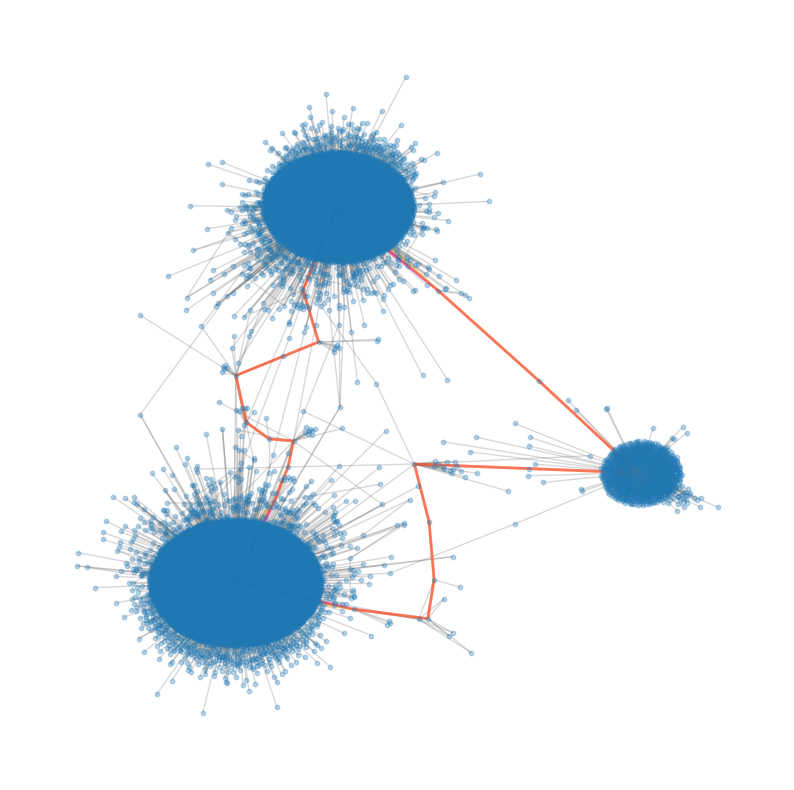

In [178]:
# Step 4: Visualize the subgraph
colors= ['#0283F8', '#FFA500','#00C49A', '#FF0059']
fig, ax = plt.subplots(figsize=(10, 10))

# Draw the subgraph
nx.draw(subgraph, pos, ax=ax, node_size=10, edge_color='gray', with_labels=False,alpha=0.3)

# Highlight the cycles
nx.draw_networkx_edges(subgraph, pos, edgelist=cycle1_edges, ax=ax, edge_color=colors[3], width=2,alpha=0.6)
nx.draw_networkx_edges(subgraph, pos, edgelist=cycle2_edges, ax=ax, edge_color=colors[1], width=2,alpha=0.4)


# Show the plot
plt.show()

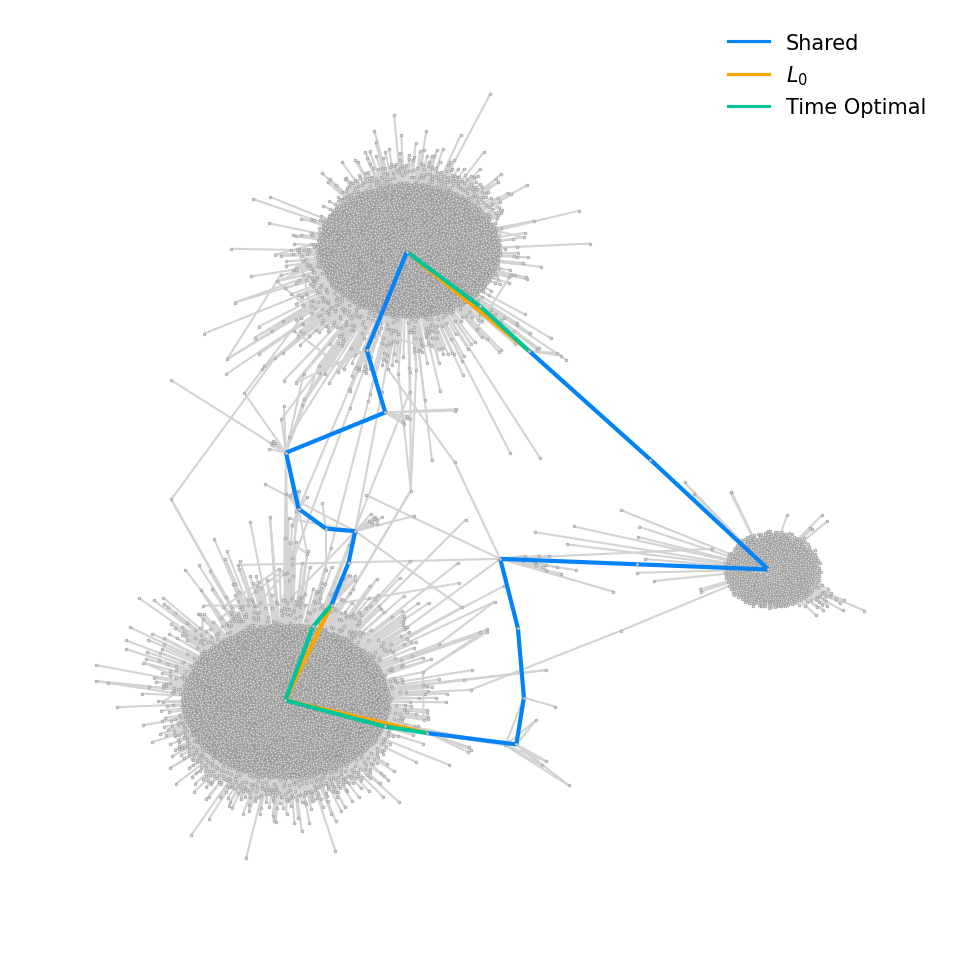

In [221]:
# Assuming subgraph, pos, cycle1_edges, and cycle2_edges are defined earlier
colors = ['#0283F8', '#FFA500', '#00C49A', '#FF0059']
fig, ax = plt.subplots(figsize=(8, 8),dpi=150)

# Draw the subgraph with lower alpha to put it in the background

edges = nx.draw_networkx_edges(subgraph, pos,edge_color='lightgray')
nodes = nx.draw_networkx_nodes(subgraph, pos,node_color='lightgray',linewidths=0.2, edgecolors="gray",node_size=2)

nodes.set_zorder(20)
edges.set_zorder(10)
# Highlight the cycles
# Cycle 1 with straight edges
cycle = nx.draw_networkx_edges(subgraph, pos, edgelist=only_cycle1, ax=ax, edge_color=colors[1], width=2, alpha=1)
cycle.set_zorder(21)
# Cycle 2 with curved edges to avoid overlap
cycle = nx.draw_networkx_edges(subgraph, pos, edgelist=only_cycle2, ax=ax, edge_color=colors[2], width=2, alpha=1)
cycle.set_zorder(21)
cycle = nx.draw_networkx_edges(subgraph, pos, edgelist=shared, ax=ax, edge_color=colors[0], width=2, alpha=1)
cycle.set_zorder(21)
nodes = nx.draw_networkx_nodes(subgraph, pos, nodelist=all_cycle_nodes,node_color='lightgray',linewidths=0.2, edgecolors="gray",node_size=2)
nodes.set_zorder(22)
plt.plot([],[],color=colors[0],label="Shared")
plt.plot([],[],color=colors[1],label="$L_0$")
plt.plot([],[],color=colors[2],label="Time Optimal")
plt.legend(frameon=False)
# Show the plot
plt.axis("off")
plt.savefig("Figures/transaction_network.png")
plt.show()

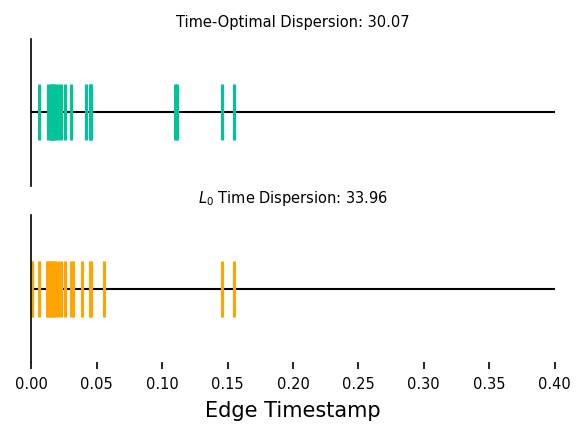

In [242]:
mosaic = """
A
B
"""
fig,ax = plt.subplot_mosaic(mosaic,figsize=(4.5, 2.8),dpi=150)


ax["A"].spines[["top","right","bottom"]].set_visible(False)
ax["A"].axhline(0,color="k",linewidth=1)
#ax.scatter([adj_matrix[a][b] for (a,b) in representative], [0]*len(representative),s=700,  color=colors["red"], marker="|",label="Representive",zorder=2)
ax["A"].scatter([adj_matrix[a][b] for (a,b) in mean_cycle], [0]*len(mean_cycle),s=700,  color=colors[2], marker="|",label="Minimal",zorder=2)
ax["A"].set_xlim((0,0.4))
ax["A"].set_title(f"Time-Optimal Dispersion: {compute_time_cost(mean_cycle):.2f}",fontsize=7)
ax["A"].tick_params(axis='x', which='major', labelsize=7)
ax["A"].set_yticks([])
ax["A"].set_xticks([])


ax["B"].spines[["top","right","bottom"]].set_visible(False)
ax["B"].axhline(0,color="k",linewidth=1)
#ax.scatter([adj_matrix[a][b] for (a,b) in representative], [0]*len(representative),s=700,  color=colors["red"], marker="|",label="Representive",zorder=2)
ax["B"].scatter([adj_matrix[a][b] for (a,b) in cycle2_edges], [0]*len(cycle2_edges),s=700,  color=colors[1], marker="|",label="Minimal",zorder=2)
ax["B"].set_xlim((0,0.4))
ax["B"].set_title(f"$L_0$ Time Dispersion: {compute_time_cost(cycle2_edges):.2f}",fontsize=7)
ax["B"].set_xlabel("Edge Timestamp")
ax["B"].tick_params(axis='x', which='major', labelsize=7)
ax["B"].set_yticks([])
plt.savefig("Figures/transaction_network_costs.png")